In [1]:
#!pip install torch torchvision transformers


In [2]:
import os
import torch
import copy
import pickle
import random
import time
import numpy as np
import seaborn as sns
import torch.nn as nn
import pandas as pd
from collections import defaultdict
from torch.utils.data import DataLoader
import torch.optim as optim
from scipy.ndimage import zoom 
import matplotlib.pyplot as plt
from scipy.signal import medfilt
from sklearn.manifold import TSNE
from transformers import ViTModel
from sklearn.model_selection import KFold, StratifiedKFold
import torchvision.transforms as transforms
from sklearn.metrics import confusion_matrix
from torch.utils.data import DataLoader, Dataset
from transformers import ViTForImageClassification 
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, roc_curve
)
from sklearn.preprocessing import label_binarize

2025-04-25 01:55:19.062477: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-04-25 01:55:19.074540: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1745564119.090287  750607 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1745564119.094510  750607 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-04-25 01:55:19.111143: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

1. Define configurations

In [3]:
# --- Configuration ---
class Config():
    def __init__(self):
        self.frame_l = 72  # Frames per sequence
        self.joint_n = 33  # Number of joints
        self.joint_d = 3  # Joint dimensions (x, y, z)
        self.clc = 3  # Number of classes
        self.feat_d = 528
        self.data_dir = r"/home/nyam/Ms_Thesis/Autism/Project_v3/Stimming/DataProcessing/v2/skel_clean_aug"
        self.dataset_info = r"/home/nyam/Ms_Thesis/Autism/Project_v3/Stimming/DataProcessing/v2/dataset_info_clean_aug.txt"
C = Config()

2. Define data processing functions

In [4]:
# --- Preprocessing Functions ---
def zoom_skeleton(p, target_l=64, joints_num=33, joints_dim=3):
    """ Rescales skeleton sequence to n frames using interpolation """
    l = p.shape[0]
    p_new = np.empty([target_l, joints_num, joints_dim])

    for m in range(joints_num):
        for n in range(joints_dim):
            p[:, m, n] = medfilt(p[:, m, n], 3)  # Apply median filter
            scale_factor = target_l / float(l)  # Ensure float division
            p_new[:, m, n] = zoom(p[:, m, n], zoom=scale_factor)[:target_l]  #  Use tuple scaling

    return p_new
    
def normalize_skeleton(p):
    p[:, :, 0] -= np.mean(p[:, :, 0])
    p[:, :, 1] -= np.mean(p[:, :, 1])
    p[:, :, 2] -= np.mean(p[:, :, 2])
    return p

3. Model functions

In [5]:
class ViTForSkeletonClassification(nn.Module):
    def __init__(self, num_classes=C.clc):
        super(ViTForSkeletonClassification, self).__init__()
        
        # Load Pretrained ViT (without classification head)
        self.vit = ViTModel.from_pretrained("google/vit-base-patch16-224", output_attentions=True)
        
        # Add a Classification Head
        hidden_dim = self.vit.config.hidden_size  # 768 for ViT-B/16
        
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, 128), 
            nn.ReLU(),
            # nn.Linear(512, 128),
            # nn.ReLU(),
            nn.Linear(128, num_classes),
            nn.Softmax()
        )
        
    def forward(self, x, return_attention=False):
        outputs = self.vit(x)  # Get transformer outputs
        last_hidden_state = outputs.last_hidden_state  # (batch_size, num_patches+1, hidden_dim)
        
        cls_token_embedding = last_hidden_state[:, 0, :]  # Extract [CLS] token representation
        logits = self.classifier(cls_token_embedding)  # Pass through FC layer
        
        if return_attention:
            return logits, outputs.attentions  # Return logits & attention maps
        
        return logits  # Return only classification outputs

In [6]:
# Fine-Tune Pretrained ViT on Our Dataset
def train_model(model, train_loader,test_loader, criterion, optimizer, num_epochs=5):
    model.train()
    for epoch in range(num_epochs):
        total_loss = 0
        correct = 0
        total = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)  # Move to GPU

            optimizer.zero_grad()
            outputs = model(inputs)  # Get logits
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

        Train_accuracy = 100 * correct / total

        # Evaluate model on the test set
        _,_,_  = evaluate_model(model, test_loader)
        
        print(f"Epoch [{epoch+1}/{num_epochs}] - Loss: {total_loss:.4f}, Training Accuracy: {Train_accuracy:.2f}%")


In [7]:
def evaluate_model(model, test_loader):
    model.eval()
    correct = 0
    total = 0
    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)  # Get predicted class index

            y_true.extend(labels.cpu().numpy())  # Store true labels
            y_pred.extend(predicted.cpu().numpy())  # Store predicted labels

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f"Test Accuracy: {accuracy:.2f}%")

    return y_true, y_pred, accuracy  # Return both true and predicted labels


4. Load dataset 

In [8]:
# Load Pretrained ViT Model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ViTForSkeletonClassification(num_classes=C.clc).to(device)

# Freeze Embeddings & First Few Layers
for param in model.vit.embeddings.parameters():
    param.requires_grad = False  # Freeze input embeddings

for param in model.vit.encoder.layer[:4].parameters():
    param.requires_grad = False  # Freeze first 3 transformer layers

# Keep last layers trainable
for param in model.vit.encoder.layer[4:].parameters():
    param.requires_grad = True  # Fine-tune deeper layers

# Always fine-tune classification head
for param in model.classifier.parameters():
    param.requires_grad = True


# Move model to GPU
model.to(device)


Some weights of ViTModel were not initialized from the model checkpoint at google/vit-base-patch16-224 and are newly initialized: ['vit.pooler.dense.bias', 'vit.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


ViTForSkeletonClassification(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTSdpaAttention(
            (attention): ViTSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linear(in

In [9]:
model_name = "ViTForSkeletonClassification"
vit_model = ViTForSkeletonClassification()  # or however you instantiated it
vit_model.load_state_dict(torch.load("ViT_best_model_fold_1.pt"))


input_shape = (1, 3, 224, 224)  # ViT-like skeleton input (RGB skeleton image)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def get_model_size(model, path="temp_model.pth"):
    torch.save(model.state_dict(), path)
    size_mb = os.path.getsize(path) / (1024 * 1024)
    os.remove(path)
    return size_mb

def measure_inference_time(model, input_tensor, runs=100, device='cpu'):
    model = model.to(device)
    model.eval()
    input_tensor = input_tensor.to(device)

    with torch.no_grad():
        for _ in range(10):  # warm-up
            _ = model(input_tensor)

        start = time.time()
        for _ in range(runs):
            _ = model(input_tensor)
        end = time.time()

    return ((end - start) / runs) * 1000  # ms

# Dummy input
dummy_input = torch.randn(*input_shape)

# Run all metrics
param_count = count_parameters(vit_model)
model_size = get_model_size(vit_model)
inference_time = measure_inference_time(vit_model, dummy_input)

# Print results
df = pd.DataFrame([{
    "Model": model_name,
    "Parameters": param_count,
    "Model Size (MB)": round(model_size, 2),
    "Inference Time (ms)": round(inference_time, 2)
}])

print(df)
#df.to_csv("vit_skeleton_model_timing.csv", index=False)


Some weights of ViTModel were not initialized from the model checkpoint at google/vit-base-patch16-224 and are newly initialized: ['vit.pooler.dense.bias', 'vit.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
`ViTSdpaAttention` is used but `torch.nn.functional.scaled_dot_product_attention` does not support `output_attentions=True` or `head_mask`. Falling back to the manual attention implementation, but specifying the manual implementation will be required from Transformers version v5.0.0 onwards. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.
/home/nyam/anaconda3/lib/python3.12/site-packages/torch/nn/modules/module.py:1739: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return self._call_impl(*args, **kwargs)


                          Model  Parameters  Model Size (MB)  \
0  ViTForSkeletonClassification    86488067            330.0   

   Inference Time (ms)  
0               127.12  


6.Plotting results

In [10]:
class SkeletonDataset(Dataset):
    def __init__(self, data_list, data_dir, label_mapping):
        """
        Args:
            data_list (list): List of tuples containing (filename, label).
            data_dir (str): Path to the directory containing skeletal .npy files.
            label_mapping (dict): Manually defined label mapping.
        """
        self.data_list = data_list
        self.data_dir = data_dir
        self.label_mapping = label_mapping  # Hardcoded label mapping
        self.resize = transforms.Resize((224, 224))

    def __len__(self):
        return len(self.data_list)

    def __getitem__(self, idx):
        filename, label_text = self.data_list[idx]  # Extract filename and label
        skeleton_path = os.path.join(self.data_dir, filename)
    
        try:
            # Load .npy skeleton data
            pose_data = np.load(skeleton_path).astype('float32')
    
            # Apply preprocessing
            pose_data = zoom_skeleton(pose_data, target_l=72, joints_num=33, joints_dim=3)
            pose_data = normalize_skeleton(pose_data)
    
            # Reshape for transformer input
            pose_data = pose_data.transpose(2, 0, 1)  # Change from (72, 33, 3) → (3, 72, 33)
    
            # Convert to PyTorch tensor
            pose_tensor = torch.tensor(pose_data, dtype=torch.float32)
            pose_tensor = self.resize(pose_tensor) 
    
            # Encode text label to numeric
            label = torch.tensor(self.label_mapping[label_text], dtype=torch.long)
    
            return pose_tensor, label
    
        except Exception as e:
            print(f"Error loading {filename}: {e}")
            return None, None  # Skip invalid samples


In [11]:
# import numpy as np
# import os
# import torch
# from torch.utils.data import Dataset
# from torchvision import transforms

# class SkeletonDataset(Dataset):
#     def __init__(self, data_list, data_dir, label_mapping):
#         """
#         Args:
#             data_list (list): List of tuples containing (filename, label).
#             data_dir (str): Path to the directory containing skeletal .npy files.
#             label_mapping (dict): Manually defined label mapping.
#         """
#         self.data_list = data_list
#         self.data_dir = data_dir
#         self.label_mapping = label_mapping
#         self.resize = transforms.Resize((224, 224))  # For ViT input

#     def __len__(self):
#         return len(self.data_list)

#     def __getitem__(self, idx):
#         filename, label_text = self.data_list[idx]
#         skeleton_path = os.path.join(self.data_dir, filename)

#         try:
#             # Load and preprocess
#             pose_data = np.load(skeleton_path).astype('float32')
#             pose_data = zoom_skeleton(pose_data, target_l=72, joints_num=33, joints_dim=3)
#             pose_data = normalize_skeleton(pose_data)

#             # Shape: (T=72, J=33, C=3) → (72, 33, 3)
#             # We’ll convert it to an image format

#             # Flatten joints and channels into 2D "skeleton image"
#             skeleton_image = pose_data.reshape(72, -1)  # (72, 99)

#             # Normalize values to [0,1] for image compatibility (optional but helps)
#             skeleton_image -= skeleton_image.min()
#             skeleton_image /= skeleton_image.max() + 1e-5

#             # Convert to a 3-channel fake RGB image by repeating or using separate channels
#             # For simplicity: duplicate the skeleton image into 3 identical channels
#             skeleton_image = np.stack([skeleton_image] * 3, axis=0)  # (3, 72, 99)

#             # Resize to (3, 224, 224)
#             skeleton_tensor = torch.tensor(skeleton_image, dtype=torch.float32)
#             skeleton_tensor = self.resize(skeleton_tensor)

#             # Encode label
#             label = torch.tensor(self.label_mapping[label_text], dtype=torch.long)

#             return skeleton_tensor, label

#         except Exception as e:
#             print(f"Error loading {filename}: {e}")
#             return None, None


In [12]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    epoch_loss = 0.0
    count = 0
    for inputs, labels in dataloader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
        count += 1
    return epoch_loss / count

def cross_validate_subject_wise(model, dataset_info, data_dir, num_folds=5, num_epochs=10, batch_size=32):
    """
    Perform 4-fold cross-validation ensuring train and test sets have no overlapping subjects.
    """
    # Hardcoded label mapping
    label_mapping = {
        "ArmFlapping": 0,
        "HeadBanging": 1,
        "Spinning": 2
    }

    # Group subjects per class
    classwise_subjects = defaultdict(lambda: defaultdict(list))

    for info in dataset_info:
        class_label = info[1]  # Class (e.g., "Spinning", "HeadBanging")
        filename = info[2]     # Extract filename
        parts = filename.split('_')
        subject_id = f"{parts[1]}_{parts[2]}"  # Unique subject identifier
        
        classwise_subjects[class_label][subject_id].append((filename, class_label))  # Store filename & label

    subject_to_label = {}
    
    # Iterate over classwise_subjects to populate subject labels
    for class_label, subjects in classwise_subjects.items():
        for subject_id in subjects.keys():
            subject_to_label[subject_id] = class_label  # Assign class label to subject
    
    # Collect unique subjects across all classes
    all_subjects = list(subject_to_label.keys())  # Unique subjects
    labels = [subject_to_label[subj] for subj in all_subjects]  # List of class labels

    # Shuffle for randomness and reproducibility
    random.seed(24)
    # random.shuffle(all_subjects)

    # Create subject-level KFold splits
    kfold = StratifiedKFold(n_splits=num_folds, shuffle=True)  # No shuffle since manually shuffled

    fold_results = []
    y_true_pred = []
    fold_histories = []
    
    for fold, (train_subj_idx, test_subj_idx) in enumerate(kfold.split(all_subjects, labels)):
        print(f"\n--- Fold {fold+1}/{num_folds} ---")

        # train_subjects = set([all_subjects[i] for i in np.concatenate((train_subj_idx, test_subj_idx[:4]))])
        # test_subjects = set([all_subjects[i] for i in np.concatenate((test_subj_idx, train_subj_idx[:4]))])

        train_subjects = set([all_subjects[i] for i in train_subj_idx])
        test_subjects = set([all_subjects[i] for i in test_subj_idx])


        # Create train and test sets ensuring mutual exclusivity
        train_list = [vid for class_subjects in classwise_subjects.values() 
                      for subj, vids in class_subjects.items() if subj in train_subjects for vid in vids]
        test_list = [vid for class_subjects in classwise_subjects.values() 
                     for subj, vids in class_subjects.items() if subj in test_subjects for vid in vids]
        print(train_subjects)
        print("------------------------------------")
        print(test_subjects)

        # Convert to PyTorch datasets with hardcoded label encoding
        train_dataset = SkeletonDataset(train_list, data_dir, label_mapping)
        test_dataset = SkeletonDataset(test_list, data_dir, label_mapping)

        # DataLoaders
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

        # Move model to device
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        model_fold = copy.deepcopy(model).to(device)  # Reset model for each fold

        # Define optimizer & loss function
        optimizer = torch.optim.AdamW(model_fold.parameters(), lr=0.0001)
        criterion = torch.nn.CrossEntropyLoss()
        
        best_accuracy = 0.0
        best_model_path = f"ViT_best_model_fold_{fold+1}.pt"
        train_losses = []
        val_losses = []
        
        for epoch in range(num_epochs):
           print(f"\nEpoch {epoch+1}/{num_epochs}")
           train_loss = train_one_epoch(model_fold, train_loader, criterion, optimizer, device)
           train_losses.append(train_loss)
        
           y_true_val, y_pred_val, val_accuracy = evaluate_model(model_fold, test_loader)
        
        # Calculate validation loss
           model_fold.eval()
           val_loss = 0.0
           with torch.no_grad():
              for inputs, labels in test_loader:
                  inputs, labels = inputs.to(device), labels.to(device)
                  outputs = model_fold(inputs)
                  loss = criterion(outputs, labels)
                  val_loss += loss.item()
           val_loss /= len(test_loader)
           val_losses.append(val_loss)
        
           print(f"Training Loss: {train_loss:.4f} | Validation Loss: {val_loss:.4f} | Validation Accuracy: {val_accuracy:.4f}")
        
           if val_accuracy > best_accuracy:
               best_accuracy = val_accuracy
               torch.save(model_fold.state_dict(), best_model_path)
               print(f"Best model saved at epoch {epoch+1} with accuracy {best_accuracy:.4f}")

        fold_histories.append({'loss': train_losses, 'val_loss': val_losses})
        # Load best model
        model_fold.load_state_dict(torch.load(best_model_path))

        # Final evaluation on test set
        y_true, y_pred, accuracy = evaluate_model(model_fold, test_loader)

        labels = ['Arm Flapping', 'HeadBanging', 'Spinning']
        
        Y_true = [labels[idx] for idx in y_true]
        Y_pred = [labels[idx] for idx in y_pred]
            
        #plot_confusion_matrix(y_true, y_pred, labels)
        y_true_pred.append([Y_true, Y_pred, labels])

        plot_confusion_matrix(Y_true, Y_pred, labels=labels)
        print(f"Accuracy for Fold {fold+1}: {accuracy:.4f}")
        fold_results.append(accuracy)

        # Visualize attention & embeddings
        sample_input, _ = test_dataset[1]
        # plot_attention(model_fold, sample_input)
        # plot_embeddings(model_fold, test_loader)

    avg_accuracy = np.mean(fold_results)
    print(f"\nFinal Cross-Validation Accuracy: {avg_accuracy:.4f}")

    return fold_results, y_true_pred, fold_histories

In [13]:
# --- Visualization: Confusion Matrix ---
def plot_confusion_matrix(y_true, y_pred, labels):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(6, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


In [14]:
def plot_attention(model, sample_input):
    model.eval()
    
    sample_input = sample_input.unsqueeze(0).to(device)  # Add batch dimension and move to GPU
    
    with torch.no_grad():
        logits, attention_maps = model(sample_input, return_attention=True)  # Extract attention 

    # Ensure attention_maps is a list of tensors
    if isinstance(attention_maps, tuple):  # Some models return tuple instead of list
        attention_maps = list(attention_maps)

    # Convert to NumPy and average across heads
    attention_maps = torch.stack(attention_maps, dim=0).cpu().numpy()  # Shape: (num_layers, batch, heads, seq_len, seq_len)
    attention_maps = attention_maps.mean(axis=2)  # Average across attention heads

    # Select first layer and first token (CLS token)
    attention = attention_maps[0, 0, :, 1:]  # Exclude CLS token

    # Plot Attention Heatmap
    plt.figure(figsize=(10, 5))
    sns.heatmap(attention, cmap="viridis", annot=False)
    plt.xlabel("Frames")
    plt.ylabel("Attention Score")
    plt.title("Self-Attention Heatmap")
    plt.show()



def plot_embeddings(model, data_loader):
    model.eval()
    features = []
    labels = []

    with torch.no_grad():
        for inputs, targets in data_loader:
            inputs = inputs.to(device)
            outputs = model(inputs) # Extract features before classification
            features.append(outputs.cpu().numpy())
            labels.append(targets.numpy())

    features = np.vstack(features)
    labels = np.hstack(labels)

    # Apply t-SNE for dimensionality reduction
    tsne = TSNE(n_components=2, random_state=42)
    reduced_features = tsne.fit_transform(features)

    # Plot t-SNE
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(reduced_features[:, 0], reduced_features[:, 1], c=labels, cmap="jet", alpha=0.7)
    plt.legend(handles=scatter.legend_elements()[0], labels=list(set(labels)), title="Classes")
    plt.title("t-SNE Visualization of Embeddings")
    plt.show()


--- Fold 1/5 ---
{'Spinning_04', 'HeadBanging_26', 'HeadBanging_46', 'ArmFlapping_28', 'Spinning_18', 'ArmFlapping_25', 'Spinning_49', 'HeadBanging_27', 'Spinning_20', 'Spinning_15', 'ArmFlapping_34', 'ArmFlapping_51', 'ArmFlapping_53', 'Spinning_58', 'HeadBanging_20', 'ArmFlapping_15', 'ArmFlapping_05', 'HeadBanging_53', 'Spinning_54', 'ArmFlapping_40', 'HeadBanging_16', 'HeadBanging_15', 'ArmFlapping_08', 'ArmFlapping_44', 'HeadBanging_54', 'HeadBanging_22', 'HeadBanging_47', 'Spinning_48', 'ArmFlapping_13', 'ArmFlapping_54', 'Spinning_60', 'Spinning_29', 'ArmFlapping_09', 'Spinning_63', 'ArmFlapping_45', 'Spinning_10', 'ArmFlapping_55', 'ArmFlapping_31', 'HeadBanging_17', 'Spinning_01', 'HeadBanging_06', 'Spinning_59', 'HeadBanging_18', 'Spinning_31', 'HeadBanging_19', 'ArmFlapping_37', 'ArmFlapping_10', 'ArmFlapping_48', 'Spinning_46', 'ArmFlapping_20', 'ArmFlapping_24', 'Spinning_07', 'Spinning_30', 'HeadBanging_05', 'HeadBanging_48', 'HeadBanging_07', 'HeadBanging_34', 'HeadBang

/home/nyam/anaconda3/lib/python3.12/site-packages/torch/nn/modules/module.py:1739: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return self._call_impl(*args, **kwargs)


Test Accuracy: 68.42%
Training Loss: 0.9088 | Validation Loss: 0.8837 | Validation Accuracy: 68.4211
Best model saved at epoch 1 with accuracy 68.4211

Epoch 2/10
Test Accuracy: 66.32%
Training Loss: 0.6868 | Validation Loss: 0.8764 | Validation Accuracy: 66.3158

Epoch 3/10
Test Accuracy: 67.37%
Training Loss: 0.5982 | Validation Loss: 0.8759 | Validation Accuracy: 67.3684

Epoch 4/10
Test Accuracy: 75.79%
Training Loss: 0.6128 | Validation Loss: 0.7875 | Validation Accuracy: 75.7895
Best model saved at epoch 4 with accuracy 75.7895

Epoch 5/10
Test Accuracy: 82.11%
Training Loss: 0.5959 | Validation Loss: 0.7386 | Validation Accuracy: 82.1053
Best model saved at epoch 5 with accuracy 82.1053

Epoch 6/10
Test Accuracy: 80.00%
Training Loss: 0.5720 | Validation Loss: 0.7533 | Validation Accuracy: 80.0000

Epoch 7/10
Test Accuracy: 75.79%
Training Loss: 0.5690 | Validation Loss: 0.7916 | Validation Accuracy: 75.7895

Epoch 8/10
Test Accuracy: 80.00%
Training Loss: 0.5687 | Validation Lo

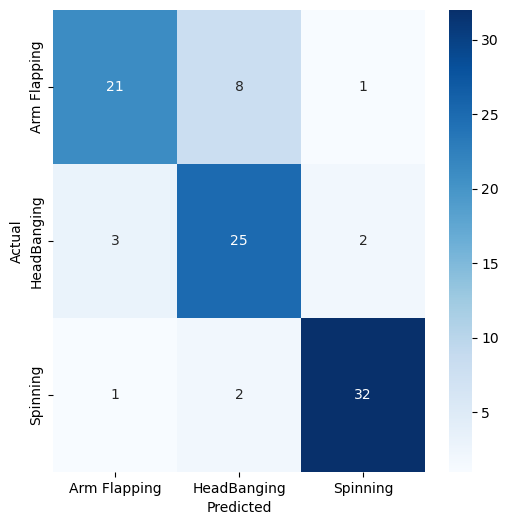

Accuracy for Fold 1: 82.1053

--- Fold 2/5 ---
{'Spinning_04', 'HeadBanging_26', 'ArmFlapping_28', 'Spinning_18', 'ArmFlapping_25', 'Spinning_28', 'Spinning_49', 'HeadBanging_27', 'Spinning_22', 'ArmFlapping_49', 'Spinning_20', 'ArmFlapping_34', 'ArmFlapping_16', 'ArmFlapping_53', 'Spinning_58', 'HeadBanging_20', 'HeadBanging_24', 'ArmFlapping_05', 'HeadBanging_28', 'HeadBanging_53', 'ArmFlapping_18', 'HeadBanging_31', 'Spinning_54', 'ArmFlapping_29', 'ArmFlapping_40', 'HeadBanging_16', 'ArmFlapping_08', 'ArmFlapping_44', 'HeadBanging_54', 'HeadBanging_22', 'HeadBanging_47', 'Spinning_48', 'ArmFlapping_54', 'Spinning_14', 'Spinning_55', 'Spinning_60', 'Spinning_29', 'ArmFlapping_09', 'Spinning_63', 'ArmFlapping_45', 'ArmFlapping_55', 'HeadBanging_10', 'HeadBanging_06', 'Spinning_01', 'HeadBanging_18', 'Spinning_59', 'ArmFlapping_37', 'Spinning_47', 'Spinning_31', 'HeadBanging_19', 'ArmFlapping_10', 'Spinning_02', 'Spinning_21', 'HeadBanging_52', 'ArmFlapping_20', 'ArmFlapping_24', 'Spi

/home/nyam/anaconda3/lib/python3.12/site-packages/torch/nn/modules/module.py:1739: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return self._call_impl(*args, **kwargs)


Test Accuracy: 68.42%
Training Loss: 0.8954 | Validation Loss: 0.8756 | Validation Accuracy: 68.4211
Best model saved at epoch 1 with accuracy 68.4211

Epoch 2/10
Test Accuracy: 74.74%
Training Loss: 0.6429 | Validation Loss: 0.7957 | Validation Accuracy: 74.7368
Best model saved at epoch 2 with accuracy 74.7368

Epoch 3/10
Test Accuracy: 73.68%
Training Loss: 0.6946 | Validation Loss: 0.8185 | Validation Accuracy: 73.6842

Epoch 4/10
Test Accuracy: 71.58%
Training Loss: 0.5927 | Validation Loss: 0.8036 | Validation Accuracy: 71.5789

Epoch 5/10
Test Accuracy: 71.58%
Training Loss: 0.5794 | Validation Loss: 0.8060 | Validation Accuracy: 71.5789

Epoch 6/10
Test Accuracy: 80.00%
Training Loss: 0.5741 | Validation Loss: 0.7604 | Validation Accuracy: 80.0000
Best model saved at epoch 6 with accuracy 80.0000

Epoch 7/10
Test Accuracy: 81.05%
Training Loss: 0.5808 | Validation Loss: 0.7521 | Validation Accuracy: 81.0526
Best model saved at epoch 7 with accuracy 81.0526

Epoch 8/10
Test Accu

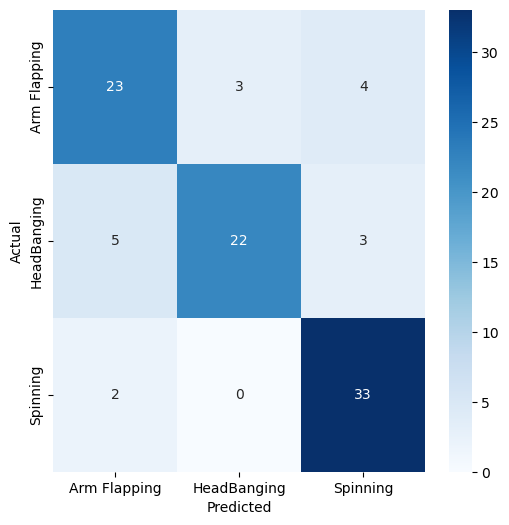

Accuracy for Fold 2: 82.1053

--- Fold 3/5 ---
{'Spinning_04', 'HeadBanging_26', 'HeadBanging_46', 'ArmFlapping_28', 'Spinning_28', 'Spinning_49', 'ArmFlapping_49', 'Spinning_22', 'ArmFlapping_16', 'Spinning_15', 'ArmFlapping_53', 'ArmFlapping_51', 'Spinning_58', 'HeadBanging_20', 'HeadBanging_24', 'ArmFlapping_15', 'HeadBanging_28', 'HeadBanging_53', 'ArmFlapping_05', 'ArmFlapping_18', 'HeadBanging_31', 'Spinning_54', 'ArmFlapping_29', 'ArmFlapping_40', 'HeadBanging_15', 'ArmFlapping_08', 'HeadBanging_54', 'HeadBanging_22', 'ArmFlapping_48', 'HeadBanging_47', 'ArmFlapping_13', 'ArmFlapping_54', 'Spinning_14', 'Spinning_55', 'Spinning_60', 'Spinning_29', 'Spinning_63', 'ArmFlapping_31', 'Spinning_10', 'HeadBanging_10', 'HeadBanging_17', 'Spinning_01', 'HeadBanging_06', 'Spinning_59', 'ArmFlapping_37', 'Spinning_47', 'Spinning_31', 'HeadBanging_19', 'ArmFlapping_10', 'Spinning_02', 'Spinning_21', 'Spinning_46', 'HeadBanging_52', 'ArmFlapping_20', 'ArmFlapping_24', 'ArmFlapping_46', 'Spi

/home/nyam/anaconda3/lib/python3.12/site-packages/torch/nn/modules/module.py:1739: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return self._call_impl(*args, **kwargs)


Test Accuracy: 77.78%
Training Loss: 0.9283 | Validation Loss: 0.7894 | Validation Accuracy: 77.7778
Best model saved at epoch 1 with accuracy 77.7778

Epoch 2/10
Test Accuracy: 81.11%
Training Loss: 0.7376 | Validation Loss: 0.7623 | Validation Accuracy: 81.1111
Best model saved at epoch 2 with accuracy 81.1111

Epoch 3/10
Test Accuracy: 74.44%
Training Loss: 0.6285 | Validation Loss: 0.7946 | Validation Accuracy: 74.4444

Epoch 4/10
Test Accuracy: 75.56%
Training Loss: 0.6372 | Validation Loss: 0.7848 | Validation Accuracy: 75.5556

Epoch 5/10
Test Accuracy: 78.89%
Training Loss: 0.5927 | Validation Loss: 0.7615 | Validation Accuracy: 78.8889

Epoch 6/10
Test Accuracy: 78.89%
Training Loss: 0.6329 | Validation Loss: 0.7589 | Validation Accuracy: 78.8889

Epoch 7/10
Test Accuracy: 86.67%
Training Loss: 0.5909 | Validation Loss: 0.6746 | Validation Accuracy: 86.6667
Best model saved at epoch 7 with accuracy 86.6667

Epoch 8/10
Test Accuracy: 86.67%
Training Loss: 0.5714 | Validation Lo

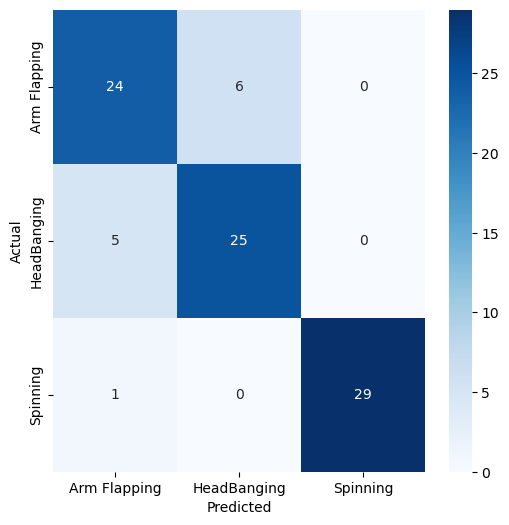

Accuracy for Fold 3: 86.6667

--- Fold 4/5 ---
{'HeadBanging_46', 'ArmFlapping_28', 'Spinning_18', 'ArmFlapping_25', 'Spinning_28', 'ArmFlapping_49', 'HeadBanging_27', 'Spinning_22', 'Spinning_20', 'Spinning_15', 'ArmFlapping_34', 'ArmFlapping_51', 'ArmFlapping_16', 'Spinning_58', 'HeadBanging_20', 'HeadBanging_24', 'ArmFlapping_15', 'HeadBanging_28', 'HeadBanging_53', 'ArmFlapping_05', 'ArmFlapping_18', 'HeadBanging_31', 'Spinning_54', 'ArmFlapping_29', 'HeadBanging_16', 'HeadBanging_15', 'ArmFlapping_08', 'ArmFlapping_44', 'HeadBanging_47', 'Spinning_48', 'ArmFlapping_13', 'Spinning_14', 'Spinning_55', 'ArmFlapping_09', 'ArmFlapping_45', 'Spinning_63', 'ArmFlapping_31', 'Spinning_10', 'ArmFlapping_55', 'HeadBanging_10', 'HeadBanging_17', 'ArmFlapping_37', 'ArmFlapping_48', 'Spinning_59', 'Spinning_47', 'HeadBanging_19', 'Spinning_02', 'Spinning_21', 'Spinning_46', 'HeadBanging_52', 'ArmFlapping_46', 'Spinning_07', 'Spinning_30', 'HeadBanging_05', 'HeadBanging_48', 'HeadBanging_07', '

/home/nyam/anaconda3/lib/python3.12/site-packages/torch/nn/modules/module.py:1739: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return self._call_impl(*args, **kwargs)


Test Accuracy: 70.00%
Training Loss: 0.9759 | Validation Loss: 0.8379 | Validation Accuracy: 70.0000
Best model saved at epoch 1 with accuracy 70.0000

Epoch 2/10
Test Accuracy: 81.11%
Training Loss: 0.7095 | Validation Loss: 0.7480 | Validation Accuracy: 81.1111
Best model saved at epoch 2 with accuracy 81.1111

Epoch 3/10
Test Accuracy: 82.22%
Training Loss: 0.6192 | Validation Loss: 0.7198 | Validation Accuracy: 82.2222
Best model saved at epoch 3 with accuracy 82.2222

Epoch 4/10
Test Accuracy: 61.11%
Training Loss: 0.6017 | Validation Loss: 0.9146 | Validation Accuracy: 61.1111

Epoch 5/10
Test Accuracy: 73.33%
Training Loss: 0.5813 | Validation Loss: 0.7926 | Validation Accuracy: 73.3333

Epoch 6/10
Test Accuracy: 74.44%
Training Loss: 0.5883 | Validation Loss: 0.7902 | Validation Accuracy: 74.4444

Epoch 7/10
Test Accuracy: 78.89%
Training Loss: 0.5688 | Validation Loss: 0.7523 | Validation Accuracy: 78.8889

Epoch 8/10
Test Accuracy: 77.78%
Training Loss: 0.5578 | Validation Lo

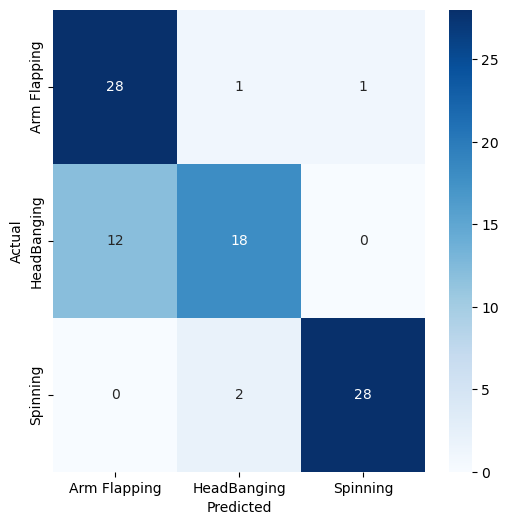

Accuracy for Fold 4: 82.2222

--- Fold 5/5 ---
{'Spinning_04', 'HeadBanging_26', 'HeadBanging_46', 'Spinning_18', 'ArmFlapping_25', 'Spinning_28', 'Spinning_49', 'HeadBanging_27', 'Spinning_22', 'ArmFlapping_49', 'Spinning_20', 'Spinning_15', 'ArmFlapping_34', 'ArmFlapping_51', 'ArmFlapping_16', 'HeadBanging_24', 'ArmFlapping_15', 'HeadBanging_28', 'ArmFlapping_18', 'HeadBanging_31', 'ArmFlapping_29', 'ArmFlapping_40', 'HeadBanging_16', 'HeadBanging_15', 'ArmFlapping_44', 'HeadBanging_54', 'HeadBanging_22', 'Spinning_48', 'ArmFlapping_13', 'ArmFlapping_54', 'Spinning_14', 'Spinning_55', 'Spinning_60', 'Spinning_29', 'ArmFlapping_09', 'ArmFlapping_45', 'ArmFlapping_31', 'Spinning_10', 'ArmFlapping_55', 'HeadBanging_10', 'HeadBanging_17', 'Spinning_01', 'HeadBanging_06', 'HeadBanging_18', 'ArmFlapping_48', 'Spinning_47', 'Spinning_31', 'ArmFlapping_10', 'Spinning_02', 'Spinning_21', 'Spinning_46', 'HeadBanging_52', 'ArmFlapping_20', 'ArmFlapping_24', 'Spinning_07', 'Spinning_30', 'HeadBa

/home/nyam/anaconda3/lib/python3.12/site-packages/torch/nn/modules/module.py:1739: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return self._call_impl(*args, **kwargs)


Test Accuracy: 91.11%
Training Loss: 0.9093 | Validation Loss: 0.7175 | Validation Accuracy: 91.1111
Best model saved at epoch 1 with accuracy 91.1111

Epoch 2/10
Test Accuracy: 84.44%
Training Loss: 0.6677 | Validation Loss: 0.7423 | Validation Accuracy: 84.4444

Epoch 3/10
Test Accuracy: 83.33%
Training Loss: 0.6181 | Validation Loss: 0.7231 | Validation Accuracy: 83.3333

Epoch 4/10
Test Accuracy: 83.33%
Training Loss: 0.5796 | Validation Loss: 0.7456 | Validation Accuracy: 83.3333

Epoch 5/10
Test Accuracy: 83.33%
Training Loss: 0.5848 | Validation Loss: 0.7113 | Validation Accuracy: 83.3333

Epoch 6/10
Test Accuracy: 83.33%
Training Loss: 0.5766 | Validation Loss: 0.7208 | Validation Accuracy: 83.3333

Epoch 7/10
Test Accuracy: 83.33%
Training Loss: 0.5618 | Validation Loss: 0.7000 | Validation Accuracy: 83.3333

Epoch 8/10
Test Accuracy: 87.78%
Training Loss: 0.5567 | Validation Loss: 0.6682 | Validation Accuracy: 87.7778

Epoch 9/10
Test Accuracy: 81.11%
Training Loss: 0.5587 | 

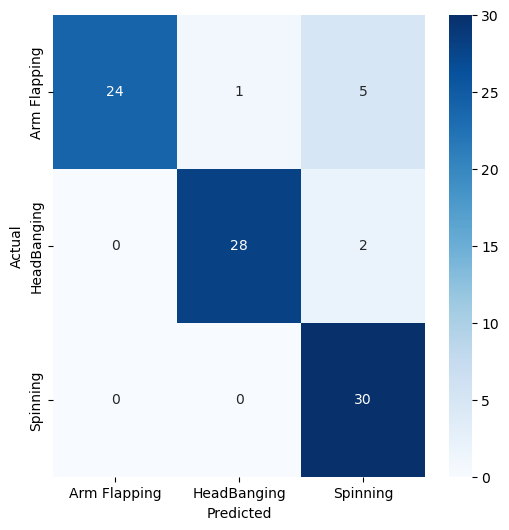

Accuracy for Fold 5: 91.1111

Final Cross-Validation Accuracy: 84.8421


In [15]:
# Function to read dataset info from file
def read_dataset_info(file_path):
    dataset_info = []
    with open(file_path, "r") as info_file:
        for line in info_file:
            # Strip any leading or trailing whitespace and split the line by tabs
            info = line.strip().split("\t")
            if info[1] != "HandAction":
                dataset_info.append(info)
    return dataset_info
    
output_info_file = C.dataset_info  # Path to dataset info
data_dir = C.data_dir  # Path where skeletal NumPy files are stored

dataset_info = (read_dataset_info(output_info_file))  # Load dataset info


# Run cross-validation
fold_results,y_true_pred, fold_histories = cross_validate_subject_wise(model, dataset_info, data_dir, num_folds=5, num_epochs=10, batch_size=16)


3

--- Fold 1 Evaluation ---
Accuracy: 0.8211
Weighted Accuracy: 0.8211
Precision: 0.8229
Recall: 0.8159
Weighted F1-score: 0.8209
AUC: 0.8637
IoC: 0.1789

--- Fold 2 Evaluation ---
Accuracy: 0.8211
Weighted Accuracy: 0.8211
Precision: 0.8239
Recall: 0.8143
Weighted F1-score: 0.8189
AUC: 0.8621
IoC: 0.1789

--- Fold 3 Evaluation ---
Accuracy: 0.8667
Weighted Accuracy: 0.8667
Precision: 0.8688
Recall: 0.8667
Weighted F1-score: 0.8676
AUC: 0.9000
IoC: 0.1333

--- Fold 4 Evaluation ---
Accuracy: 0.8222
Weighted Accuracy: 0.8222
Precision: 0.8409
Recall: 0.8222
Weighted F1-score: 0.8183
AUC: 0.8667
IoC: 0.1778

--- Fold 5 Evaluation ---
Accuracy: 0.9111
Weighted Accuracy: 0.9111
Precision: 0.9254
Recall: 0.9111
Weighted F1-score: 0.9112
AUC: 0.9333
IoC: 0.0889


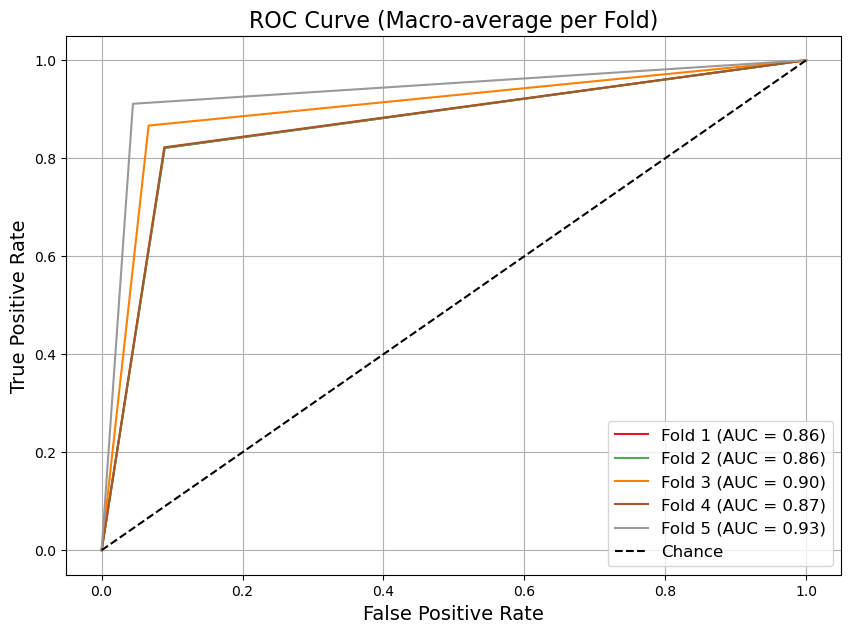


--- Final Cross-Validation Results ---
Accuracy: Mean = 0.8484, Std = 0.0359
Weighted Accuracy: 0.8484
Precision: 0.8564
Recall: 0.8460
Weighted F1-score: 0.8474
AUC: 0.8852
IoC: 0.1516


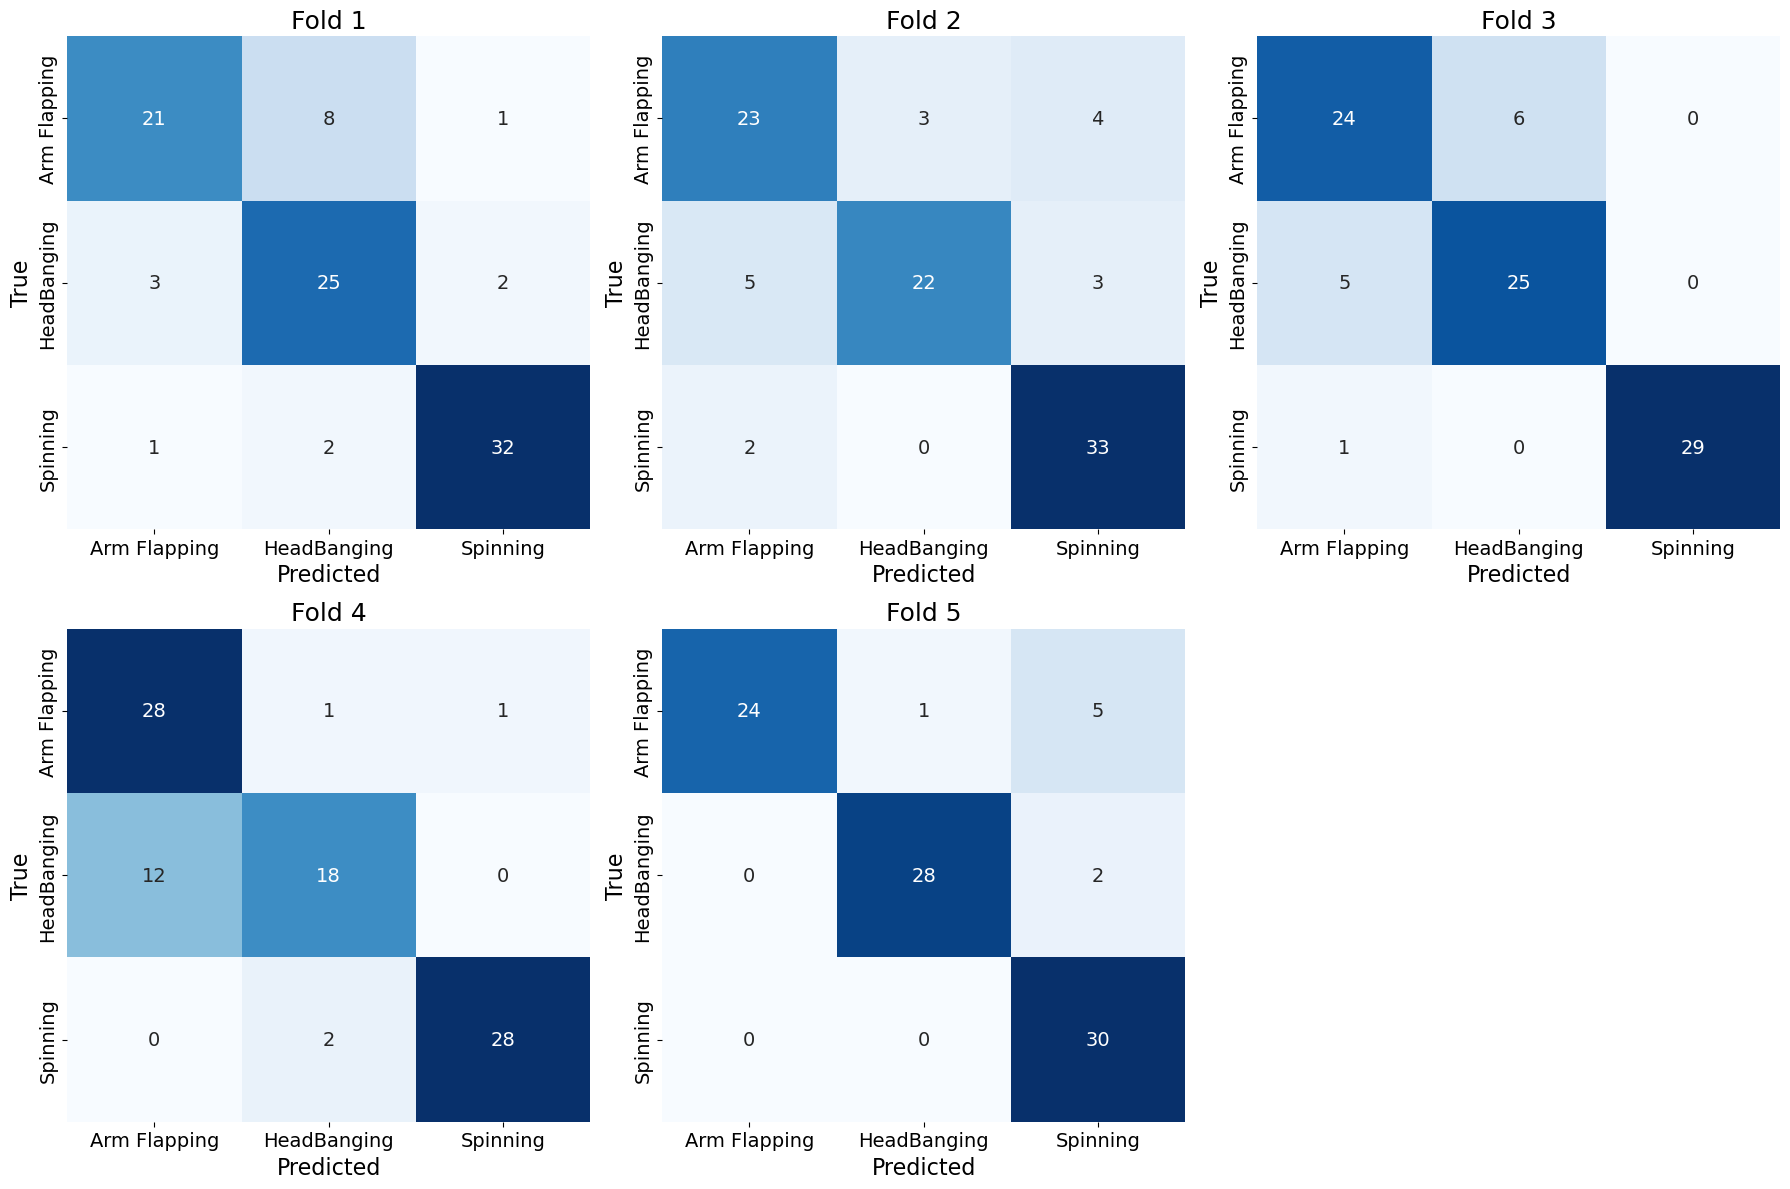

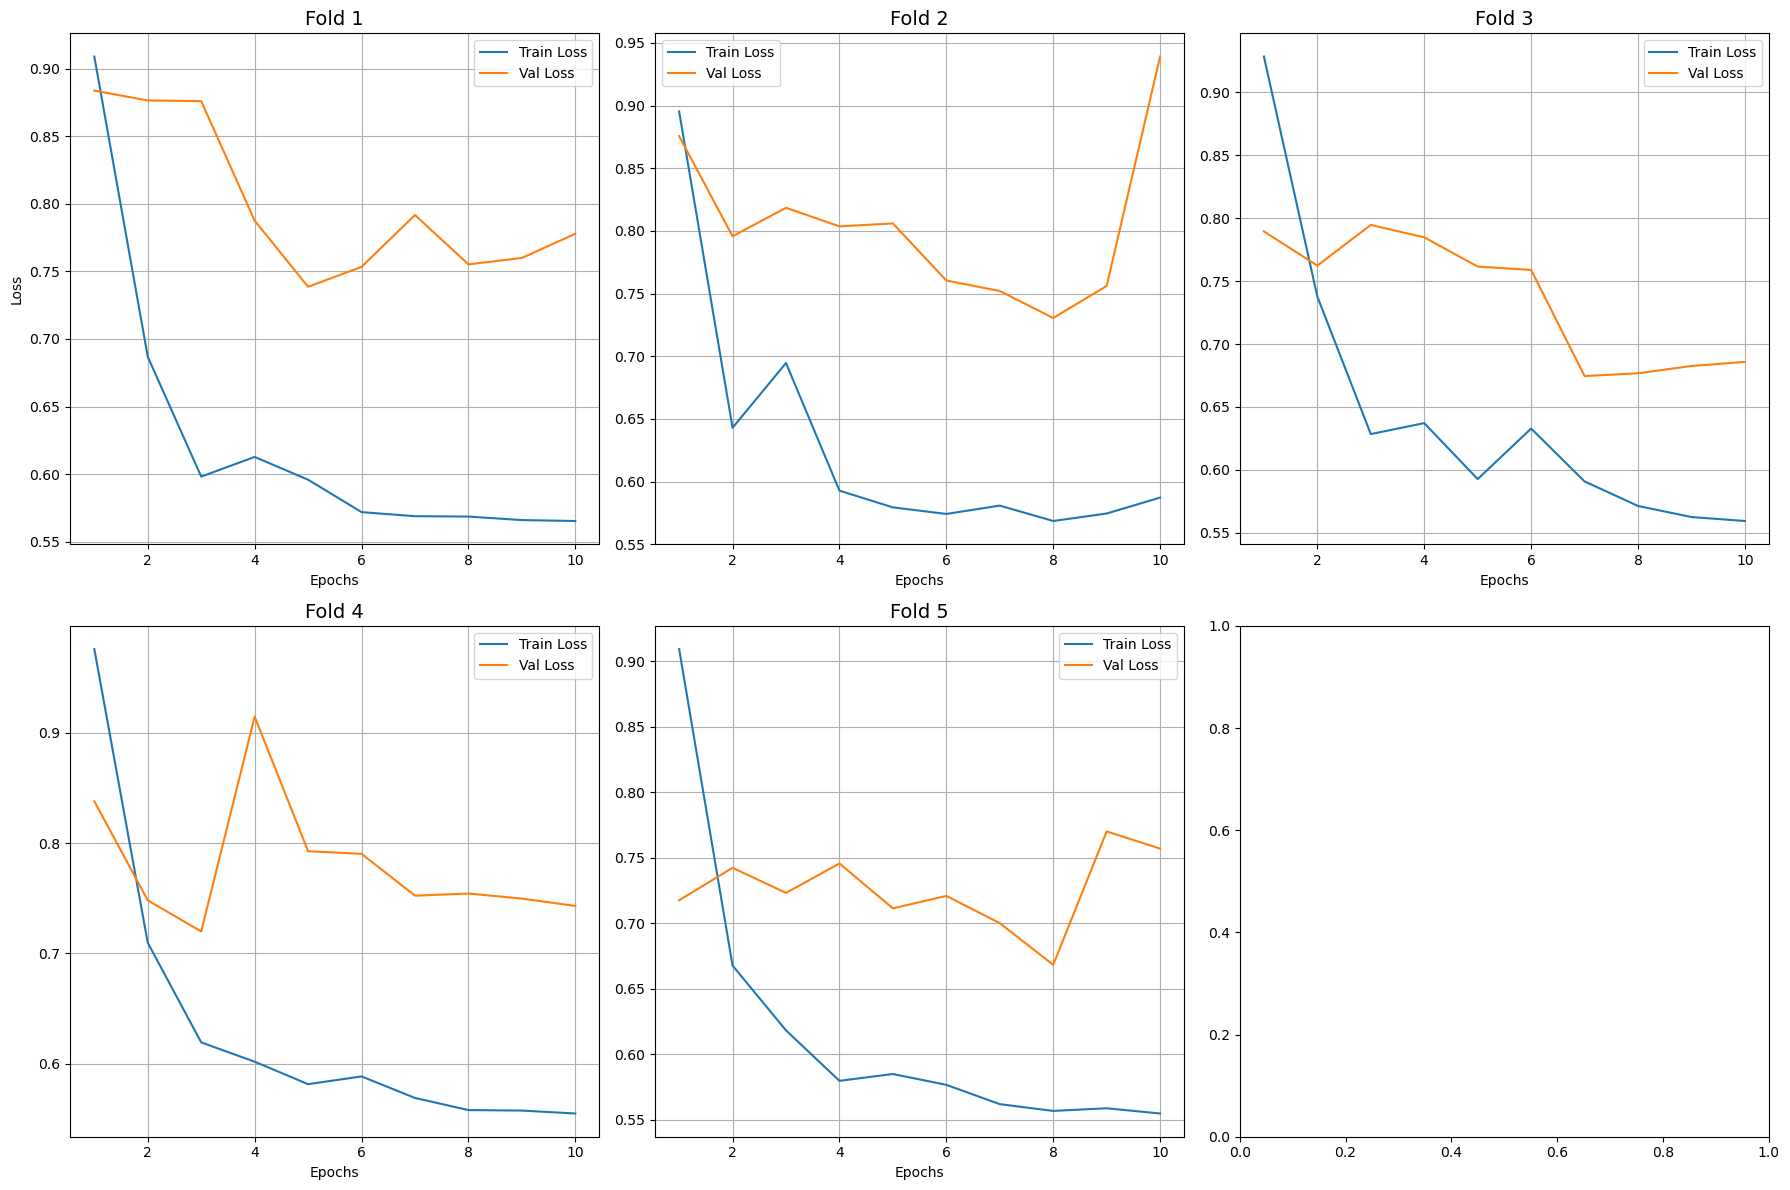

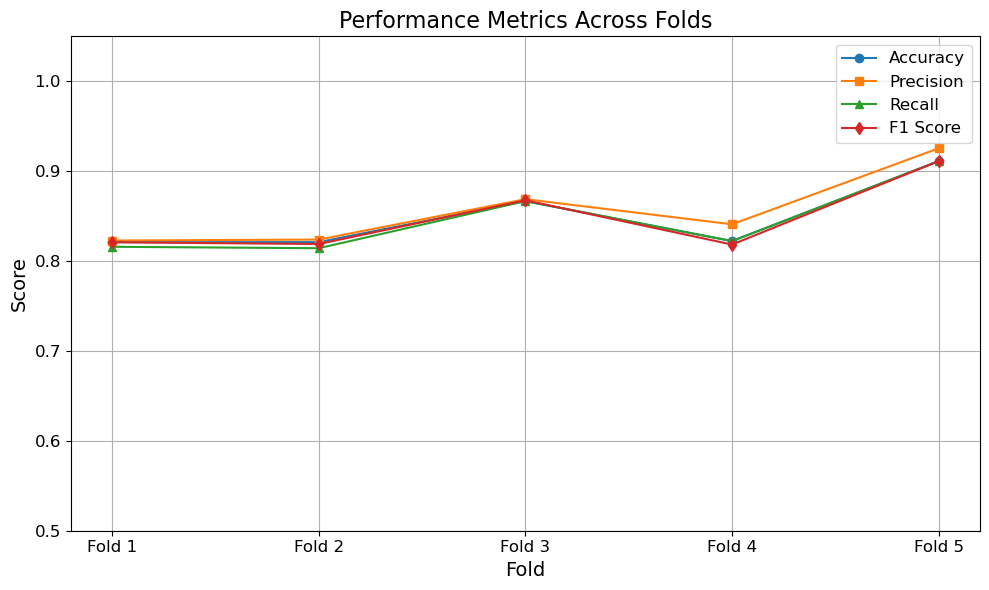

In [16]:
# Initialize
conf_matrices = []
accuracies = []
weighted_accuracies = []
precisions = []
recalls = []
weighted_f1_scores = []
auc_scores = []
ioc_scores = []

num_classes = len(y_true_pred[0][2])  # from labels
print(num_classes)
all_labels = y_true_pred[0][2]        # consistent labels

# Color palette for ROC
colors = plt.cm.Set1(np.linspace(0, 1, len(y_true_pred)))

# For ROC plotting
plt.figure(figsize=(10, 7))
for fold, data in enumerate(y_true_pred):
    y_true, y_pred, labels = data

    print(f"\n--- Fold {fold+1} Evaluation ---")
    # print(y_true)
    # print(all_labels)

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    conf_matrices.append(cm)

    # Accuracy
    acc = accuracy_score(y_true, y_pred)
    weighted_acc = np.sum(np.diag(cm)) / np.sum(cm)
    accuracies.append(acc)
    weighted_accuracies.append(weighted_acc)

    # Precision, recall, F1
    precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
    recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
    weighted_f1 = f1_score(y_true, y_pred, average='weighted')

    precisions.append(precision)
    recalls.append(recall)
    weighted_f1_scores.append(weighted_f1)

    # AUC (Macro)
    try:
        y_true_bin = label_binarize(y_true, classes=labels)
        y_pred_bin = label_binarize(y_pred, classes=labels)
        auc = roc_auc_score(y_true_bin, y_pred_bin, average='macro', multi_class="ovr")
        auc_scores.append(auc)

        # Macro-average ROC (manual, since you want visualization)
        fpr, tpr, _ = roc_curve(y_true_bin.ravel(), y_pred_bin.ravel())
        plt.plot(fpr, tpr, label=f'Fold {fold+1} (AUC = {auc:.2f})', color=colors[fold])
    except ValueError:
        auc_scores.append(np.nan)

    # IoC
    ioc = 1 - acc
    ioc_scores.append(ioc)

    # Fold scores
    print(f"Accuracy: {acc:.4f}")
    print(f"Weighted Accuracy: {weighted_acc:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"Weighted F1-score: {weighted_f1:.4f}")
    print(f"AUC: {auc:.4f}")
    print(f"IoC: {ioc:.4f}")

# ===== Plot 2: ROC Curve Summary =====
plt.plot([0, 1], [0, 1], 'k--', label='Chance')
plt.xlabel('False Positive Rate', fontsize=14)
plt.ylabel('True Positive Rate', fontsize=14)
plt.title('ROC Curve (Macro-average per Fold)', fontsize=16)
plt.legend(fontsize=12)
plt.grid(True)
plt.show()

# ===== Final Results =====
print("\n--- Final Cross-Validation Results ---")
print(f"Accuracy: Mean = {np.mean(accuracies):.4f}, Std = {np.std(accuracies):.4f}")
print(f"Weighted Accuracy: {np.mean(weighted_accuracies):.4f}")
print(f"Precision: {np.mean(precisions):.4f}")
print(f"Recall: {np.mean(recalls):.4f}")
print(f"Weighted F1-score: {np.mean(weighted_f1_scores):.4f}")
print(f"AUC: {np.nanmean(auc_scores):.4f}")
print(f"IoC: {np.mean(ioc_scores):.4f}")

# ===== Plot 1: Confusion Matrices =====
fig, axs = plt.subplots(2, 3, figsize=(18, 12))
axs = axs.flatten()

for i, cm in enumerate(conf_matrices):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=all_labels, yticklabels=all_labels,
                ax=axs[i], cbar=False, annot_kws={"size": 14})
    axs[i].set_title(f'Fold {i+1}', fontsize=18)
    axs[i].set_xlabel('Predicted', fontsize=16)
    axs[i].set_ylabel('True', fontsize=16)
    axs[i].tick_params(axis='both', labelsize=14)

if len(conf_matrices) < 6:
    fig.delaxes(axs[-1])

plt.tight_layout()
plt.show()

# Create 5 subplots loss functions (2 row, 3 columns)
fig, axs = plt.subplots(2,3, figsize=(18, 12))
axs = axs.flatten()
for i, hist in enumerate(fold_histories):
    epochs = range(1, len(hist['loss']) + 1)
    axs[i].plot(epochs, hist['loss'], label='Train Loss')
    axs[i].plot(epochs, hist['val_loss'], label='Val Loss')
    axs[i].set_title(f'Fold {i+1}', fontsize=14)
    axs[i].set_xlabel('Epochs')
    if i == 0:
        axs[i].set_ylabel('Loss')
    axs[i].grid(True)
    axs[i].legend()

plt.tight_layout()
plt.show()

# ===== Plot 3: Accuracy, Precision, Recall, F1 =====
folds = [f'Fold {i+1}' for i in range(len(y_true_pred))]

plt.figure(figsize=(10, 6))
plt.plot(folds, accuracies, marker='o', label='Accuracy')
plt.plot(folds, precisions, marker='s', label='Precision')
plt.plot(folds, recalls, marker='^', label='Recall')
plt.plot(folds, weighted_f1_scores, marker='d', label='F1 Score')

plt.title('Performance Metrics Across Folds', fontsize=16)
plt.xlabel('Fold', fontsize=14)
plt.ylabel('Score', fontsize=14)
plt.ylim(0.5, 1.05)
plt.grid(True)
plt.legend(fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()


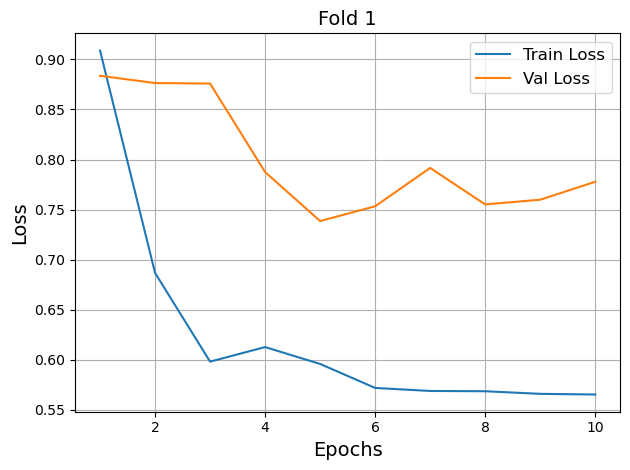

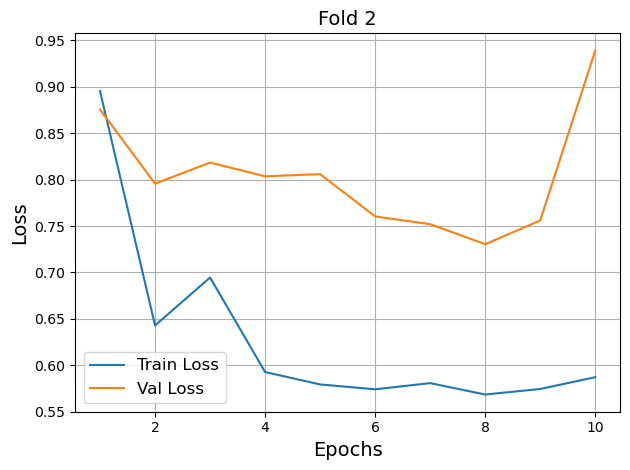

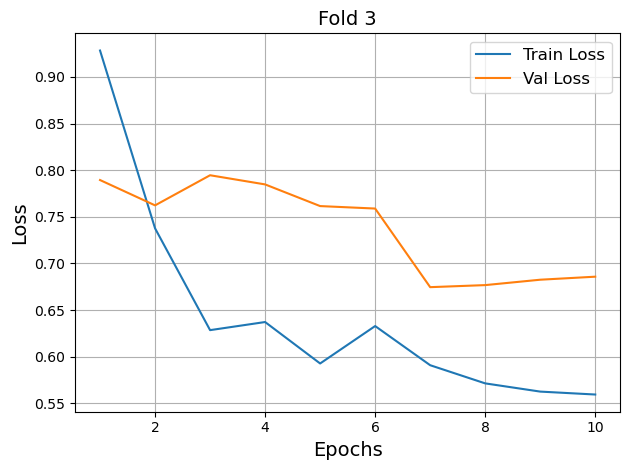

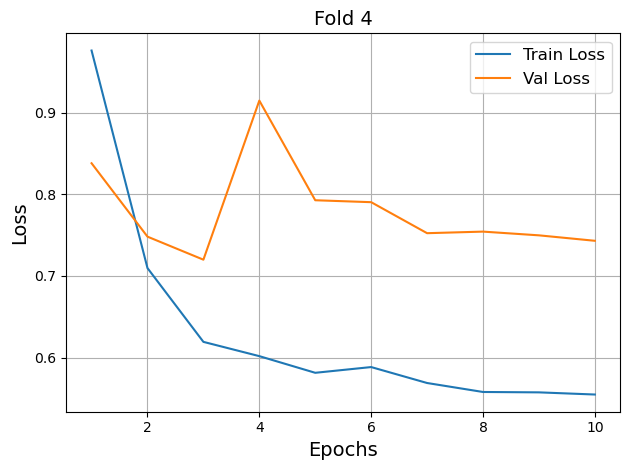

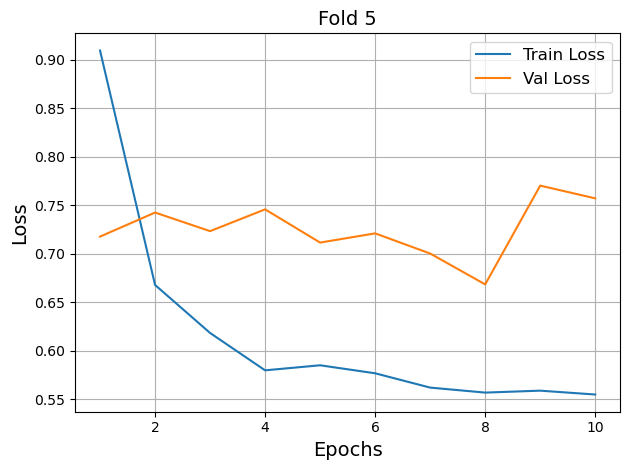

In [17]:
for i, hist in enumerate(fold_histories):
    epochs = range(1, len(hist['loss']) + 1)
    
    plt.plot(epochs, hist['loss'], label='Train Loss')
    plt.plot(epochs, hist['val_loss'], label='Val Loss')
    plt.title(f'Fold {i+1}', fontsize=14)
    if i == 0:
        axs[i].set_ylabel('Loss')
    axs[i].grid(True)
    axs[i].legend()
    
    plt.xlabel('Epochs', fontsize=14)
    plt.ylabel('Loss', fontsize=14)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.tight_layout()
    plt.show()